# Gaussian conjugate inference

**Gabriel Trabelsi**

A compact completed example from the integration notebook: a standard normal prior, Gaussian observations with unit variance, posterior densities and the posterior mean.

**Academic context:** UM4MA379, Statistique Computationnelle, Sorbonne Université, Master 1, 2025-2026. Course: A. Guyader; practical sessions: M. Sangnier. Implementations and completed experiments by Gabriel Trabelsi, developed within the supplied exercise framework.

Figures and outputs are retained from the original notebook. Random draws and timings may differ on a new run; historical execution counters have been cleared.

In [ ]:
import numpy as np  # Vectors and matrices
from scipy import stats  # Probability distributions
import matplotlib.pyplot as plt  # Plots

# Enable nice plots
import matplotlib as mpl
try:
    mpl.style.use('seaborn-v0_8')
except:
    mpl.style.use('seaborn')
mpl.rcParams['image.cmap'] = 'plasma'
nice_hist = dict(bins='auto', density=True, ec='w')


## Posterior update

For observations $X_1,\ldots,X_n$, the posterior is normal with mean $\sum_iX_i/(n+1)$ and variance $1/(n+1)$. The plots show the update after 3, 5 and 10 observations.

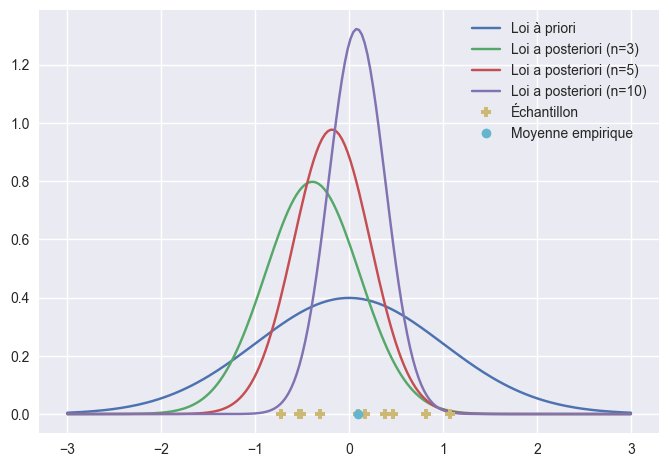

In [ ]:
prior = stats.norm(loc=0, scale=1)

# Loi ptheta
theta = prior.rvs()
ptheta = stats.norm(loc=theta, scale=1)

n = 10
X = ptheta.rvs(size=n)

# Affichage de la densité a priori
x = np.linspace(-3, 3, num=200)

y = prior.pdf(x)
plt.plot(x, y, label="Loi à priori")

for m in [3, 5, 10]:
    posterior = stats.norm(
        loc=m * np.mean(X[:m]) / (m + 1),
        scale=1 / np.sqrt(m + 1),
    )
    plt.plot(x, posterior.pdf(x), label=f"Loi a posteriori (n={m})")

plt.plot(X, [0]*X.size, "P", label="Échantillon")
plt.plot(X.mean(), 0, "o", label="Moyenne empirique")
plt.legend();


## Posterior mean

The squared-error Bayes estimate is the posterior mean.

In [ ]:
theta_n = np.sum(X)/(n+1)

print(theta)
print(theta_n)


0.08362503447327006
